In [1]:
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
import numpy as np
import torchvision

### CIFAR-10 dataset

In [3]:
import torchvision.transforms as transforms
transform_train = transforms.Compose([
    transforms.RandomCrop(32, padding=4),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize((0.4914, 0.4822, 0.4465), (0.2023, 0.1994, 0.2010)),
])

transform_test = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.4914, 0.4822, 0.4465), (0.2023, 0.1994, 0.2010)),
])

train_dataset = torchvision.datasets.CIFAR10(root='./content/',train=True, download=False, transform=transform_train)
test_dataset = torchvision.datasets.CIFAR10(root="./content/", train=False, download=False, transform=transform_test)
classes = train_dataset.classes
classes

['airplane',
 'automobile',
 'bird',
 'cat',
 'deer',
 'dog',
 'frog',
 'horse',
 'ship',
 'truck']

### STL-10 Dataset

```
import torchvision.transforms as transforms
from torch.utils.data import random_split
transform_train = transforms.Compose([
    transforms.RandomCrop(96, padding=12),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize((0.4467, 0.4398, 0.4066),(0.2603, 0.2566, 0.2713)),
])

transform_test = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.4467, 0.4398, 0.4066),(0.2603, 0.2566, 0.2713)),
])

dataset = torchvision.datasets.STL10(root='./content/',split="train", download=True, transform=transform_train)
train_dataset, test_dataset = random_split(
    dataset,
    [4000, 1000],
    generator=torch.Generator().manual_seed(42)
)

```
mean = torch.tensor((0.4467, 0.4398, 0.4066))
std  = torch.tensor((0.2603, 0.2566, 0.2713))
images, target = train_dataset[27]
img = images.permute(1, 2, 0)
img = img * std + mean
print(img.shape)
plt.imshow(img)
plt.axis("off")
plt.show()

### ImageNet-100 Dataset

```
!pip install -q datasets
from datasets import load_dataset

train_dataset = load_dataset("clane9/imagenet-100", split="train")
test_dataset = load_dataset("clane9/imagenet-100", split="validation")


def apply_train_transform(examples):
    examples["pixel_values"] = [transform_train(img.convert("RGB")) for img in examples["image"]]
    return examples
def apply_test_transform(examples):
    examples["pixel_values"] = [transform_test(img.convert("RGB")) for img in examples["image"]]
    return examples

### Data transformations

In [4]:
import torch
from torchvision.transforms import v2

transform_train = v2.Compose([
    v2.RandomResizedCrop(224, scale=(0.08, 1.0), interpolation=v2.InterpolationMode.BICUBIC),
    v2.RandomHorizontalFlip(p=0.5),
    v2.ToImage(),
    v2.ToDtype(torch.float32, scale=True),
    v2.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
])

transform_test = v2.Compose([
    v2.Resize(256, interpolation=v2.InterpolationMode.BICUBIC),
    v2.CenterCrop(224),
    v2.ToImage(),
    v2.ToDtype(torch.float32, scale=True),
    v2.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

```
def apply_train_transform(examples):
    examples["pixel_values"] = [transform_train(img.convert("RGB")) for img in examples["image"]]
    return examples
def apply_test_transform(examples):
    examples["pixel_values"] = [transform_test(img.convert("RGB")) for img in examples["image"]]
    return examples

train_dataset.set_transform(apply_train_transform)
test_dataset.set_transform(apply_test_transform)

```
import random

feats = train_dataset.features['label']
classes = feats.names

ix = random.randint(0, len(test_dataset))
x = test_dataset[ix]
img_arr = (x["pixel_values"])
img_arr = img_arr.permute(1, 2, 0).numpy()

mean=np.array([0.485, 0.456, 0.406])
std=np.array([0.229, 0.224, 0.225])
img_arr = img_arr * std + mean
img_arr = np.clip(img_arr, 0, 1)

print(classes[x["label"]])
print(img_arr.shape)
plt.imshow(img_arr)
plt.axis('off')
plt.show()

### Simple visualization of image PaTches

Selected image index: 68


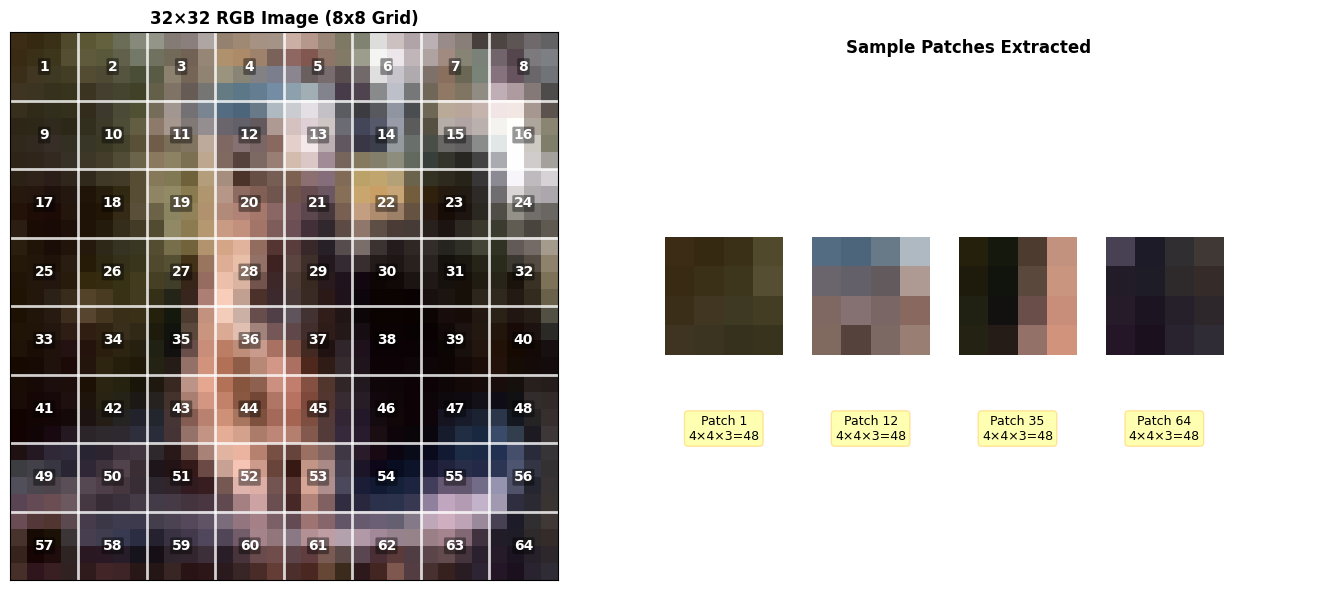

In [5]:
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.patches import Rectangle, FancyArrowPatch
import random

imgs, targets = next(iter(test_loader))
idx = random.randint(0, len(imgs) - 1)
print(f"Selected image index: {idx}")
img_arr = plot_tensor_img(imgs[idx])

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

ax0 = axes[0]
ax0.imshow(img_arr)
ax0.set_title("32×32 RGB Image (8x8 Grid)", fontsize=12, weight='bold')

for i in range(1, 8):
    ax0.axhline(y=i*4 - 0.5, color='white', linewidth=2, alpha=0.8)
    ax0.axvline(x=i*4 - 0.5, color='white', linewidth=2, alpha=0.8)

patch_num = 1
for row in range(8):
    for col in range(8):
        x = col * 4 + 1.5
        y = row * 4 + 1.5
        ax0.text(
            x, y, str(patch_num),
            ha='center', va='center',
            fontsize=10, color='white', weight='bold',
            bbox=dict(boxstyle='round,pad=0.1', facecolor='black', alpha=0.4, edgecolor='none')
        )
        patch_num += 1

ax0.set_xticks([])
ax0.set_yticks([])

ax1 = axes[1]
ax1.set_xlim(0, 14)
ax1.set_ylim(0, 10)
ax1.axis('off')
ax1.set_title("Sample Patches Extracted", fontsize=12, weight='bold')

sample_patch_coords = [(0, 0), (1, 3), (4, 2), (7, 7)]
display_positions = [2, 5, 8, 11]

for x_pos, (r, c) in zip(display_positions, sample_patch_coords):
    patch = img_arr[r*4:(r+1)*4, c*4:(c+1)*4, :]
    
    p_id = r * 8 + c + 1
    
    ax1.imshow(patch, extent=[x_pos-1.2, x_pos+1.2, 4, 6.4])
    
    ax1.text(x_pos, 2.5, f'Patch {p_id}\n4×4×3=48', ha='center', va='center', fontsize=9, 
            bbox=dict(boxstyle='round,pad=0.3', facecolor='yellow', alpha=0.3, edgecolor='orange'))

plt.tight_layout()
plt.savefig('fig_3a_patch_decomposition.png', dpi=200, bbox_inches='tight')
plt.show()


### ViT architecture

#### Convert image to patches and flatten 

In [6]:
class Patching(nn.Module):

    def __init__(self, in_channels, patch_size, image_size, dim):
        super().__init__()
        assert image_size % patch_size == 0
        self.projection = nn.Conv2d(in_channels=in_channels, out_channels=dim, kernel_size=patch_size, stride=patch_size, padding=0)
        self.num_patches = (image_size//patch_size)**2

    def forward(self, x):
        x = self.projection(x)
        return x.flatten(2).transpose(1,2)

#### Transformer Block

In [7]:
class Block(nn.Module):

    def __init__(self, dim, num_heads, mlp_ratio, dropout=0.1):
        super().__init__()
        self.ln1 = nn.LayerNorm(dim)
        self.attn = nn.MultiheadAttention(dim, num_heads, batch_first=True, dropout=dropout)
        self.ln2 = nn.LayerNorm(dim)
        self.mlp = nn.Sequential(
            nn.Linear(dim, dim * mlp_ratio),
            nn.GELU(),
            nn.Linear(dim * mlp_ratio, dim),
            nn.Dropout(dropout)
        )

    def forward(self, x, return_attn=False):
        a, aw = self.attn(self.ln1(x), self.ln1(x), self.ln1(x), need_weights=return_attn, average_attn_weights=True)
        x = x + a
        x = x + self.mlp(self.ln2(x))
        # print(aw)
        return x, aw

#### ViT main pipeline

In [8]:
class VIT(nn.Module):

    def __init__(self,dim, num_classes, img_size=32, patch_size=4, in_channels=3, depth=12, num_heads=12, mlp_ratio=4):
        super().__init__()
        scale = 0.02
        self.patch = Patching(in_channels, patch_size,img_size, dim)
        num_patches = self.patch.num_patches
        self.cls_token = nn.Parameter(torch.randn(1, 1, dim) * scale)
        self.pos_emb = nn.Parameter(torch.randn(1, num_patches + 1, dim) * scale )
        self.blocks = nn.ModuleList([
            Block(dim, num_heads, mlp_ratio) for _ in range(depth)
        ])
        self.ln = nn.LayerNorm(dim)
        self.head = nn.Linear(dim, num_classes)

    def forward(self, x, return_attn=False):
        x = self.patch(x)
        cls = self.cls_token.expand(x.size(0), -1, -1)
        x = torch.cat([cls, x], dim=1)
        # print(self.pos_emb)
        x = x + self.pos_emb
        A = []
        for blk in self.blocks:
            x, aw = blk(x, return_attn=return_attn)
            if return_attn:
                A.append(aw)
        x = self.ln(x)
        cls_token = x[:, 0,:]
        logits = self.head(cls_token)
        if return_attn:
            return logits, A
        return logits

### Save / Load checkpoint

In [9]:
import os

CHECKPOINT_PATH="/kaggle/working/checkpoint_emb192.pth"

def load_checkpoint(model, optimizer, filename=CHECKPOINT_PATH):
    start_epoch = 0
    train_lossi = []
    test_lossi = []
    metrics_history = {
        'test_acc': [],
        'test_precision': [],
        'test_recall': [],
        'test_f1': []
    }
    best_test_loss = float('inf')

    if os.path.exists(filename):
        print(f"checkpoint exists...")
        checkpoint = torch.load(filename, map_location=device)

        model.load_state_dict(checkpoint['model_state_dict'])
        optimizer.load_state_dict(checkpoint['optimizer_state_dict'])
        start_epoch = checkpoint['epoch']

        train_lossi = checkpoint.get('train_lossi', [])
        test_lossi = checkpoint.get('test_lossi', [])
        best_test_loss = checkpoint.get('best_test_loss', float('inf'))
        metrics_history = checkpoint.get('metrics_history', metrics_history)

        print(f"resumed from epoch {start_epoch}")
    else:
        print("No checkpoint found.")

    return start_epoch, train_lossi, test_lossi, best_test_loss, metrics_history

def save_checkpoint(model, optimizer, epoch, train_lossi, test_lossi, best_test_loss, metrics_history, filename=CHECKPOINT_PATH):
    checkpoint = {
        'epoch': epoch,
        'model_state_dict': model.state_dict(),
        'optimizer_state_dict': optimizer.state_dict(),
        'train_lossi': train_lossi,
        'test_lossi': test_lossi,
        'best_test_loss': best_test_loss,
        'metrics_history': metrics_history
    }
    torch.save(checkpoint, filename)
    print(f"checkpoint saved at epoch {epoch} to '{filename}'")

In [15]:
# os.remove(CHECKPOINT_PATH)

```
# for ImageNet and other datasets
def collator(batch):
    pixel_values = torch.stack([item["pixel_values"] for item in batch])

    labels = torch.tensor([item["label"] for item in batch], dtype=torch.long)

    return {
        "pixel_values": pixel_values,
        "labels": labels
    }


In [10]:
from torch.utils.data import DataLoader
import os
cores_avail = os.cpu_count()
print(f"Total CPU Cores: {cores_avail}")
BATCH_SIZE = 128
train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=cores_avail,
    pin_memory=True,
    # collate_fn=collator
)
test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=cores_avail,
    pin_memory=True,
    # collate_fn=collator
)
print(f'Train dataset: {len(train_dataset)} images')

Total CPU Cores: 4
Train dataset: 50000 images


In [17]:
# images, labels = next(iter(train_loader)).values()
# images.shape

In [11]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
device

device(type='cuda')

### Load model checkpoint (if avail), call ViT pipeline, initialize train hyper params (opt, loss etc)

In [12]:
import torch.optim as optim
import torch.amp as amp
import os

CHECKPOINT_PATH = "./checkpoint_emb192.pth"

root, _ = os.path.splitext(CHECKPOINT_PATH)
emb = int(root.split('emb')[1])

vit_classifier = VIT(
    dim=emb,
    num_classes=len(classes),
    img_size=32,
    patch_size=4,
    depth=6,
    num_heads=2,
    mlp_ratio=4
).to(device)
criterion = nn.CrossEntropyLoss()
optimizer = optim.AdamW(vit_classifier.parameters(), lr=3e-4, weight_decay=0.05)
scaler = amp.GradScaler('cuda')
start_epoch, train_lossi, test_lossi, best_test_loss, metrics_history = load_checkpoint(vit_classifier, optimizer, filename=CHECKPOINT_PATH)

print(f"Current History Length: {len(train_lossi)}")
print(f"Best Test Loss: {best_test_loss}")

checkpoint exists...
resumed from epoch 36
Current History Length: 36
Best Test Loss: 0.5718325357648391


In [12]:
%pip install -q torchmetrics

Note: you may need to restart the kernel to use updated packages.


### Tracking metrics

In [14]:
from torchmetrics import Precision, Recall, F1Score, Accuracy

num_classes = len(classes)
acc_metric = Accuracy(task="multiclass", num_classes=num_classes, average="macro").to(device)
precision_metric = Precision(task='multiclass', num_classes=num_classes, average="macro").to(device)
recall_metric = Recall(task='multiclass', num_classes=num_classes, average="macro").to(device)
f1score_metric = F1Score(task='multiclass', num_classes=num_classes, average="macro").to(device)

acc_tr = acc_metric.compute()
precision_tr = precision_metric.compute()
recall_tr = recall_metric.compute()
f1score_tr = f1score_metric.compute()

### Main test loop

In [25]:
epochs = 50
def train_func():
    global best_test_loss   # lowest test loss to save checkpoint  
    for epoch in range(start_epoch, epochs):
        vit_classifier.train()
        running_loss = torch.tensor(0.0, device=device)
        epoch_loss = torch.tensor(0.0, device=device)
        for batch_idx, (images, targets) in enumerate(train_loader):
            images = images.to(device)
            targets = targets.to(device)

            optimizer.zero_grad()

            with amp.autocast('cuda'):
                logits = vit_classifier(images, return_attn=False)
                loss = criterion(logits, targets)

            _, pred_tr = logits.max(1)

            acc_metric.update(pred_tr, targets)
            precision_metric.update(pred_tr, targets)
            recall_metric.update(pred_tr, targets)
            f1score_metric.update(pred_tr, targets)

            scaler.scale(loss).backward()

            scaler.step(optimizer)
            scaler.update()

            running_loss += loss
            epoch_loss += loss

        avg_train_loss = epoch_loss / len(train_loader)
        train_lossi.append(avg_train_loss.item())

        acc_tr = acc_metric.compute()
        precision_tr = precision_metric.compute()
        recall_tr = recall_metric.compute()
        f1score_tr = f1score_metric.compute()

        print(f"After Epoch [{epoch+1}/{epochs}]")
        print(f"TRAIN STATS step [{batch_idx+1}/{len(train_loader)}]\nloss: {avg_train_loss:.4f},"
        f"accuracy: {acc_tr:.4f}, precision: {precision_tr:.4f}, recall: {recall_tr:.4f}, f1_score: {f1score_tr:.4f}")
        running_loss = 0.0


        acc_metric.reset()
        precision_metric.reset()
        recall_metric.reset()
        f1score_metric.reset()

        vit_classifier.eval()
        test_loss = 0.0

        with torch.no_grad():
            for images, targets in test_loader:
                images, targets = images.to(device), targets.to(device)
                with amp.autocast('cuda'):
                    logits = vit_classifier(images)
                    loss = criterion(logits, targets)
                test_loss += loss.item()
                _, predicted = logits.max(1)

                acc_metric.update(preds=predicted, target=targets)
                precision_metric.update(preds=predicted, target=targets)
                recall_metric.update(preds=predicted, target=targets)
                f1score_metric.update(preds=predicted, target=targets)

        avg_test_loss = test_loss / len(test_loader)
        test_acc = acc_metric.compute().item()
        test_precision = precision_metric.compute().item()
        test_recall = recall_metric.compute().item()
        test_f1 = f1score_metric.compute().item()

        metrics_history['test_acc'].append(test_acc)
        metrics_history['test_precision'].append(test_precision)
        metrics_history['test_recall'].append(test_recall)
        metrics_history['test_f1'].append(test_f1)
        test_lossi.append(avg_test_loss)


        print(f"TEST STATS\nloss: {avg_test_loss:.4f},"
        f"accuracy: {test_acc:.4f}, precision: {test_precision:.4f}, recall: {test_recall:.4f}, f1_score: {test_f1:.4f}")

        if avg_test_loss <= best_test_loss:
            best_test_loss = avg_test_loss
            save_checkpoint(vit_classifier, optimizer, epoch + 1, train_lossi, test_lossi, best_test_loss, metrics_history, filename=CHECKPOINT_PATH)

        acc_metric.reset()
        precision_metric.reset()
        recall_metric.reset()
        f1score_metric.reset()

In [26]:
train_func()

After Epoch [50/75]
TRAIN STATS step [391/391]
loss: 0.5695,accuracy: 0.7955, precision: 0.7949, recall: 0.7955, f1_score: 0.7951
TEST STATS
loss: 0.6229,accuracy: 0.7840, precision: 0.7842, recall: 0.7840, f1_score: 0.7819
After Epoch [51/75]
TRAIN STATS step [391/391]
loss: 0.5707,accuracy: 0.7989, precision: 0.7983, recall: 0.7989, f1_score: 0.7985
TEST STATS
loss: 0.6231,accuracy: 0.7876, precision: 0.7900, recall: 0.7876, f1_score: 0.7882
After Epoch [52/75]
TRAIN STATS step [391/391]
loss: 0.5643,accuracy: 0.7985, precision: 0.7980, recall: 0.7985, f1_score: 0.7981
TEST STATS
loss: 0.6332,accuracy: 0.7838, precision: 0.7847, recall: 0.7838, f1_score: 0.7815
After Epoch [53/75]
TRAIN STATS step [391/391]
loss: 0.5581,accuracy: 0.8013, precision: 0.8008, recall: 0.8013, f1_score: 0.8010
TEST STATS
loss: 0.6262,accuracy: 0.7847, precision: 0.7869, recall: 0.7847, f1_score: 0.7842
After Epoch [54/75]
TRAIN STATS step [391/391]
loss: 0.5541,accuracy: 0.8031, precision: 0.8026, recall:

### Plot model metrics (train/test loss, test accuracy, test precision, test recall, test f1 score) over epochs

Image saved


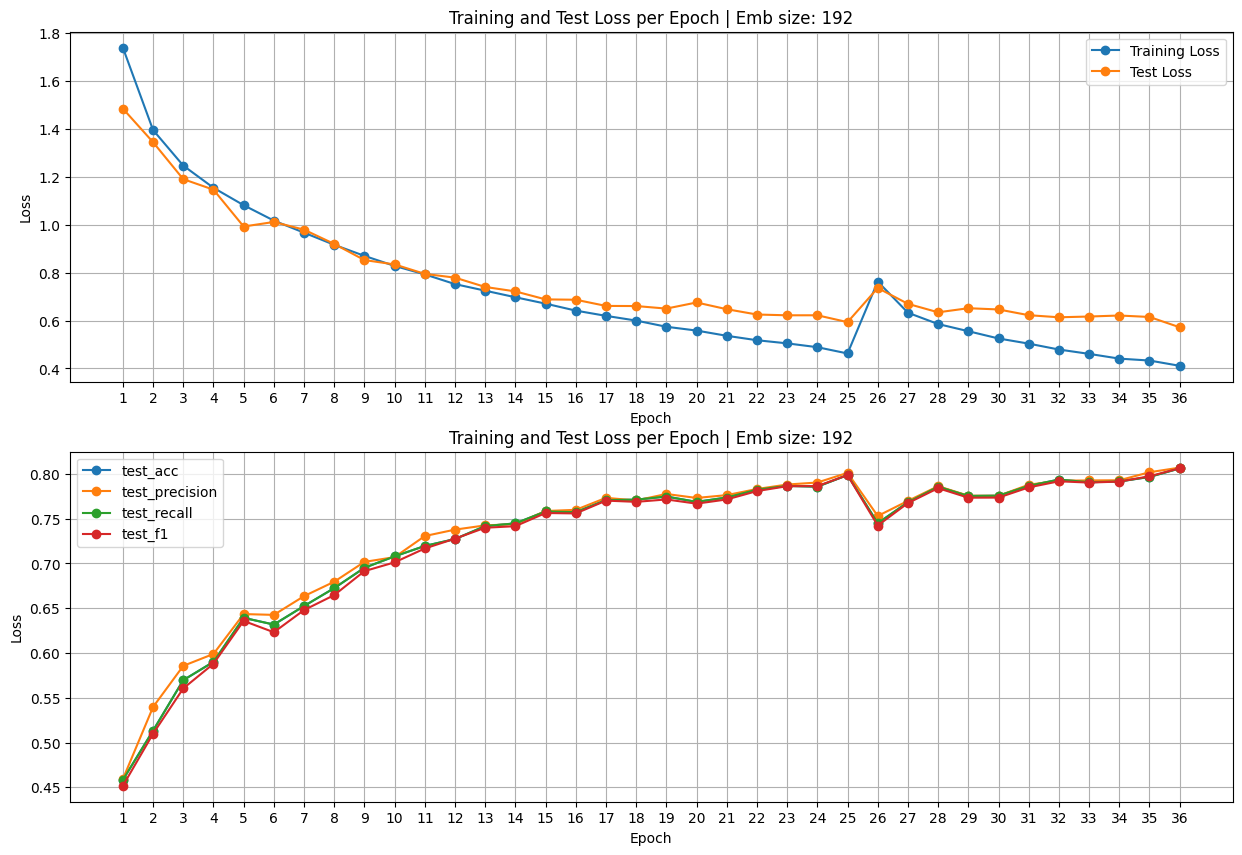

In [13]:
epochs_range = range(1, len(train_lossi) + 1)

fig, (ax1, ax2) = plt.subplots(nrows=2, ncols=1, figsize=(15, 10))

ax1.plot(epochs_range, train_lossi, label='Training Loss', marker='o')
ax1.plot(epochs_range, test_lossi, label='Test Loss', marker='o')
for i in metrics_history.keys():
    ax2.plot(epochs_range, metrics_history[i], label=i, marker='o')

for ax in (ax1, ax2):
    ax.set_title(f'Training and Test Loss per Epoch | Emb size: {emb}')
    ax.set_xlabel('Epoch')
    ax.set_ylabel('Loss')
    ax.legend()
    ax.grid(True)
    ax.set_xticks(epochs_range)
try:
    plt.savefig("./graphs/metrics_graph_192.png")
    print("Image saved")
except Exception as e:
    print(e)
plt.show()

Image saved


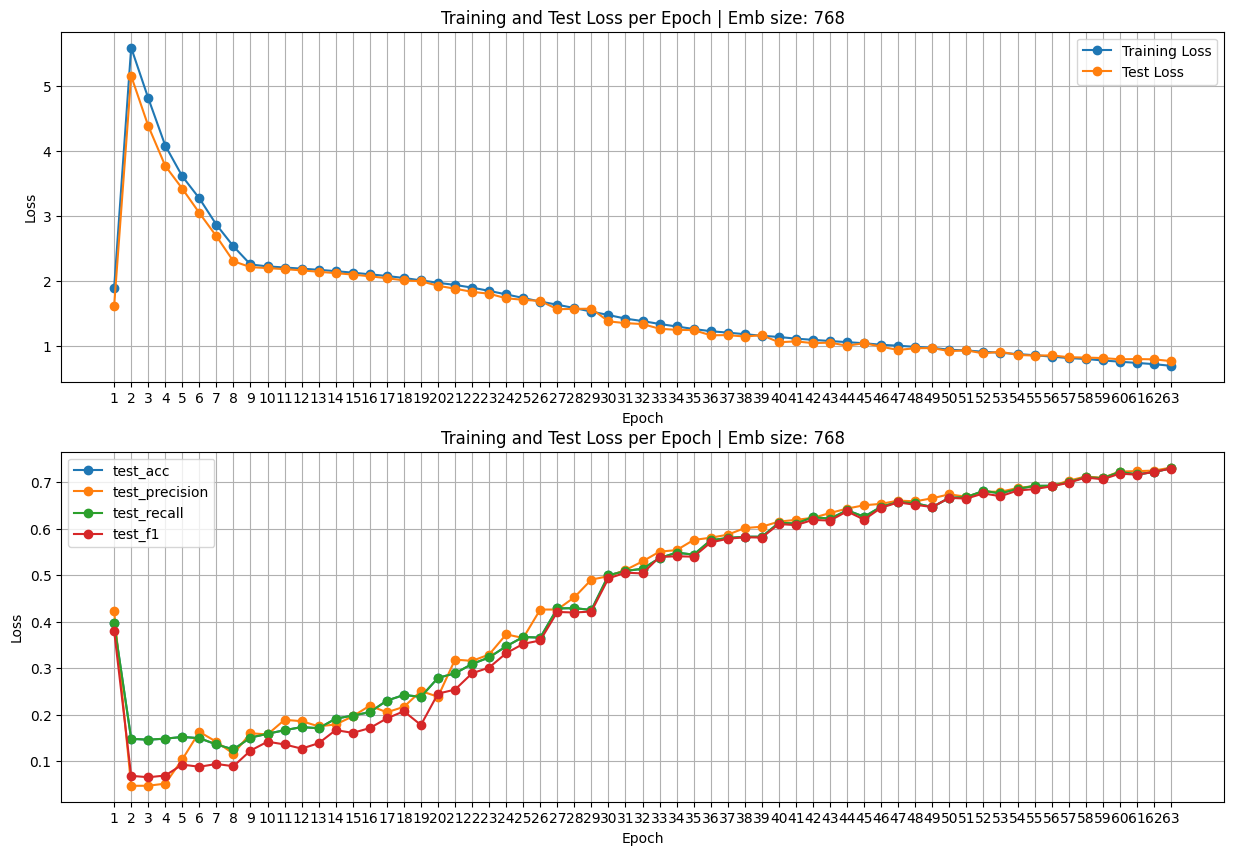

In [19]:
# Plot for different checkpoint

# epochs_range = range(1, len(train_lossi) + 1)

# fig, (ax1, ax2) = plt.subplots(nrows=2, ncols=1, figsize=(15, 10))

# ax1.plot(epochs_range, train_lossi, label='Training Loss', marker='o')
# ax1.plot(epochs_range, test_lossi, label='Test Loss', marker='o')
# for i in metrics_history.keys():
#     ax2.plot(epochs_range, metrics_history[i], label=i, marker='o')

# for ax in (ax1, ax2):
#     ax.set_title(f'Training and Test Loss per Epoch | Emb size: {emb}')
#     ax.set_xlabel('Epoch')
#     ax.set_ylabel('Loss')
#     ax.legend()
#     ax.grid(True)
#     ax.set_xticks(epochs_range)
# try:
#     plt.savefig(f"./graphs/metrics_graph_{emb}.png")
#     print("Image saved")
# except Exception as e:
#     print(e)
# plt.show()

In [14]:
def plot_tensor_img(img):
    """ 
    Simple method to convert image array to plottable image tensor. 
    The returned image can be directly plotted by: plt.imshow()
    """
    img = img.permute(1,2,0).cpu().numpy()
    mean = np.array([0.4914, 0.4822, 0.4465])
    std = np.array([0.2023, 0.1994, 0.2010])

    img_display = std * img + mean
    img_display = np.clip(img_display, 0, 1)
    return img_display

### Predicated logits bar plot

Image saved


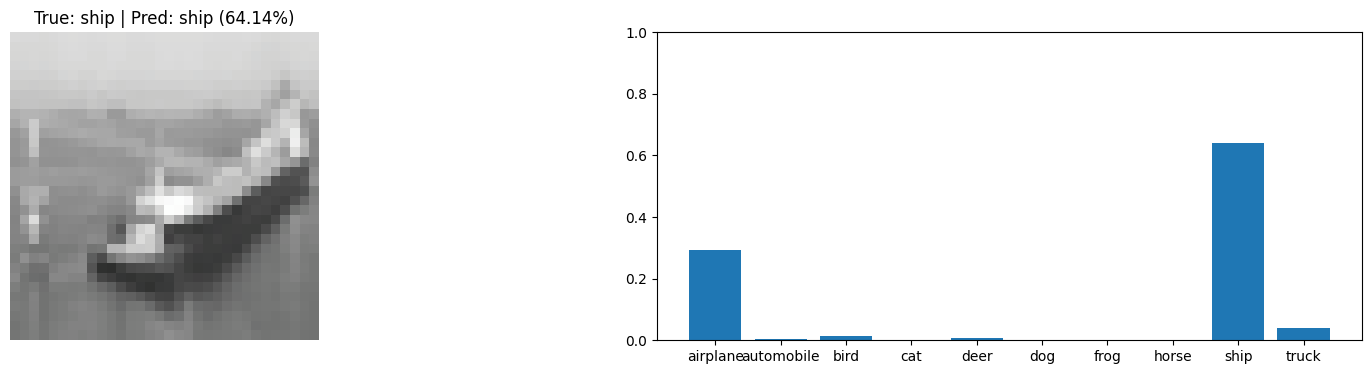

In [15]:
# Run model on random image and plot probability along all classes

import torch.nn.functional as F
import random

# random.seed(42) # uncomment for deterministic image

test_imgs, test_targets = next(iter(test_loader))
idx = random.randint(0, len(test_targets) - 1)
input_tensor = test_imgs[idx].unsqueeze(0).to(device)

vit_classifier.eval()
with torch.no_grad():
    logits = vit_classifier(input_tensor)
    probs = F.softmax(logits, dim=-1)
    pred_idx = torch.argmax(probs, dim=-1).item()
    conf = probs[0][pred_idx].item()

true_label = classes[test_targets[idx]]
pred_label = classes[pred_idx]

img_display = plot_tensor_img(test_imgs[idx])

fig, (ax1, ax2) = plt.subplots(nrows=1, ncols=2, figsize=(20,4))

ax1.imshow(img_display)
ax1.set_title(f"True: {true_label} | Pred: {pred_label} ({conf:.2%})")
ax1.axis('off')

probs.shape
y = probs.cpu().view(10).detach().numpy()
ax2.bar(classes, y)
ax2.set_ylim(0,1)
try:
    plt.savefig("./graphs/bar_softmax.png")
    print("Image saved")
except Exception as e:
    print(e)
plt.show()


### Experiment 1: Attention Map Visualization

In [16]:
import torch

def attn_rollout_func(attentions):
    """  Attention rollout implementation, return tensor of all  """
    attn_rollout = []
    dev = attentions[0].device
    I = torch.eye(attentions[0].shape[-1], device=dev)
    prod = I
    for attn_map in attentions:
        attn_map = 0.5 * attn_map + 0.5 * I
        attn_norm = attn_map / attn_map.sum(dim=-1, keepdim=True)
        prod = attn_norm @ prod
        attn_rollout.append(prod)

    return torch.stack(attn_rollout)


def attn_rollout_heatmaps(attn_matrices, img_size, num_patches):
    attn_rollouts = attn_rollout_func(attn_matrices)
    attn_rollouts.shape
    
    attn_map = attn_rollouts[-1]
    
    cls_attention = attn_map[0, 0, 1:].cpu().numpy()
    side_len = int(np.sqrt(num_patches))
    cls_attention = cls_attention.reshape(side_len, side_len)
    
    # Normalize
    cls_attention = (cls_attention - cls_attention.min()) / (cls_attention.max() - cls_attention.min())
    
    # Resize and Blur
    cls_attention_resized = Image.fromarray((cls_attention * 255).astype(np.uint8)).resize((img_size, img_size), resample=Image.BICUBIC)
    hm_no_blur =np.array(cls_attention_resized) / 255.0
    cls_attention_resized = cls_attention_resized.filter(ImageFilter.GaussianBlur(radius=4))
    heatmap = np.array(cls_attention_resized) / 255.0
    
    return heatmap, hm_no_blur

actual class: bird
pred class: bird
Image saved


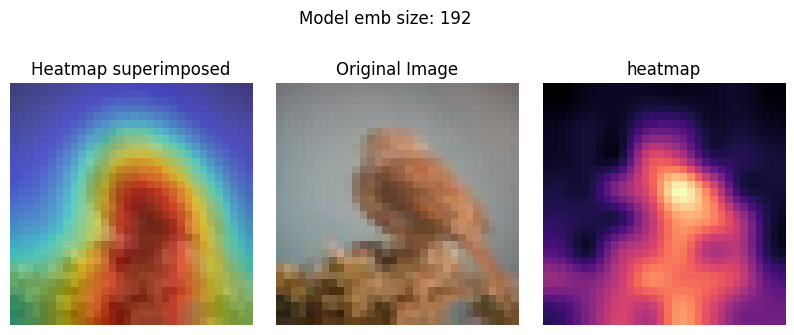

In [17]:
import torch.nn.functional as F
import random
from PIL import Image,ImageFilter
torch.manual_seed(42)
torch.cuda.manual_seed_all(42)
np.random.seed(42)
# random.seed(42)

imgs, targets= next(iter(test_loader))
for idx in range(0, len(imgs)):
    idx = random.randint(0, len(imgs)-1)
    input_tensor = imgs[idx].unsqueeze(0).to(device)

    vit_classifier.eval()
    with torch.no_grad():
        logits, A = vit_classifier(input_tensor,return_attn=True)
        probs = F.softmax(logits, dim=-1)
        pred_idx = torch.argmax(probs, dim=-1).item()
        conf = probs[0][pred_idx].item()
    if classes[targets[idx]] == classes[pred_idx]:
        break

print("actual class:",classes[targets[idx]])
print("pred class:",classes[pred_idx])

img_display = plot_tensor_img(imgs[idx])
DISPLAY_SIZE = (256, 256)
img_pil = Image.fromarray((img_display * 255).astype(np.uint8))
img_display_upscaled = img_pil.resize(DISPLAY_SIZE, resample=Image.BICUBIC)

num_attn_maps = len(A)
num_cols=3
num_of_patches=64
img_size=32
num_rows = 1

h1, h2 = attn_rollout_heatmaps(A, img_size, num_of_patches)

fig, (ax1, ax2, ax3) = plt.subplots(num_rows, num_cols, figsize=(10, 4))
plt.suptitle(f"Model emb size: {emb}")


ax1.imshow(img_display)
ax1.imshow(h1, cmap='jet', alpha=0.45)
ax1.set_title(f'Heatmap superimposed')
ax1.axis('off')

ax2.imshow(img_display)
ax2.set_title('Original Image')
ax2.axis('off')

ax3.imshow(h2, cmap='magma')
ax3.set_title('heatmap')
ax3.axis('off')

plt.subplots_adjust(wspace=0.1, hspace=0.3)

try:
    plt.savefig("./graphs/attn_rollout.png")
    print("Image saved")
except Exception as e:
    print(e)
plt.show()

### Experiment 2: Layer-wise predication from CLS token

In [18]:
def get_per_layer_predictions(model, input_tensor):
    """forward hook function to extract CLS token get preds"""
    model.eval()
    layer_logits = []

    def hook_fn(module, input_args, output):
        if isinstance(output, tuple):
            hidden_states = output[0]
        else:
            hidden_states = output

        cls_token = hidden_states[:, 0, :]

        with torch.no_grad():
            logit = model.head(model.ln(cls_token))

        layer_logits.append(logit)

    handles = []
    for block in model.blocks:
        handle = block.register_forward_hook(hook_fn)
        handles.append(handle)

    with torch.no_grad():
        final_logits = model(input_tensor)

    for handle in handles:
        handle.remove()

    return final_logits, layer_logits

In [19]:
def get_preds(img):
    input_tensor = img.unsqueeze(0).to(device)
    
    vit_classifier.eval()
    layer_wise = []
    
    with torch.no_grad():
        final_logits, A = vit_classifier(input_tensor, return_attn=True)
        final_probs = F.softmax(final_logits, dim=-1)
        pred_idx = torch.argmax(final_probs, dim=-1).item()
        conf = final_probs[0][pred_idx].item()
    return classes[pred_idx], A

### Get images per class

In [20]:
import torch
from torch.utils.data import Subset

class ClassSampler:
    """ Class defined to get set of images per class"""
    def __init__(self, dataset, num_per_class=1):
        self.dataset = dataset
        self.num_per_class = num_per_class
        self.targets = torch.tensor(dataset.targets)
        self.locked = set()
        self.indices = {}
        self._resample_all()
    
    def _resample_all(self):
        for c in range(10):
            if c not in self.locked:
                cls_idx = (self.targets == c).nonzero(as_tuple=True)[0]
                perm = torch.randperm(len(cls_idx))
                self.indices[c] = cls_idx[perm[:self.num_per_class]]
    
    def lock(self, class_idx): # locked image doesn't change on reshuffle of data
        self.locked.add(class_idx)
    
    def unlock(self, class_idx):
        self.locked.discard(class_idx)
    
    def reshuffle(self):
        self._resample_all()
    
    def get_subsets(self):
        return [Subset(self.dataset, self.indices[c]) for c in range(10)]



In [21]:
selector = ClassSampler(test_dataset, num_per_class=1)
subsets = selector.get_subsets()

In [38]:
# simple method to hand pick images from dataset
# selector.lock(0)
# selector.lock(1)
# selector.lock(2)
# selector.unlock(3)
# selector.lock(4)
# selector.lock(5)
# selector.lock(6)
# selector.lock(7)
# selector.lock(8)
# selector.lock(9)

In [22]:
# run to shuffle data

# selector.reshuffle()
# subsets = selector.get_subsets()

Image saved in ./graphs/per-layer-pred.png


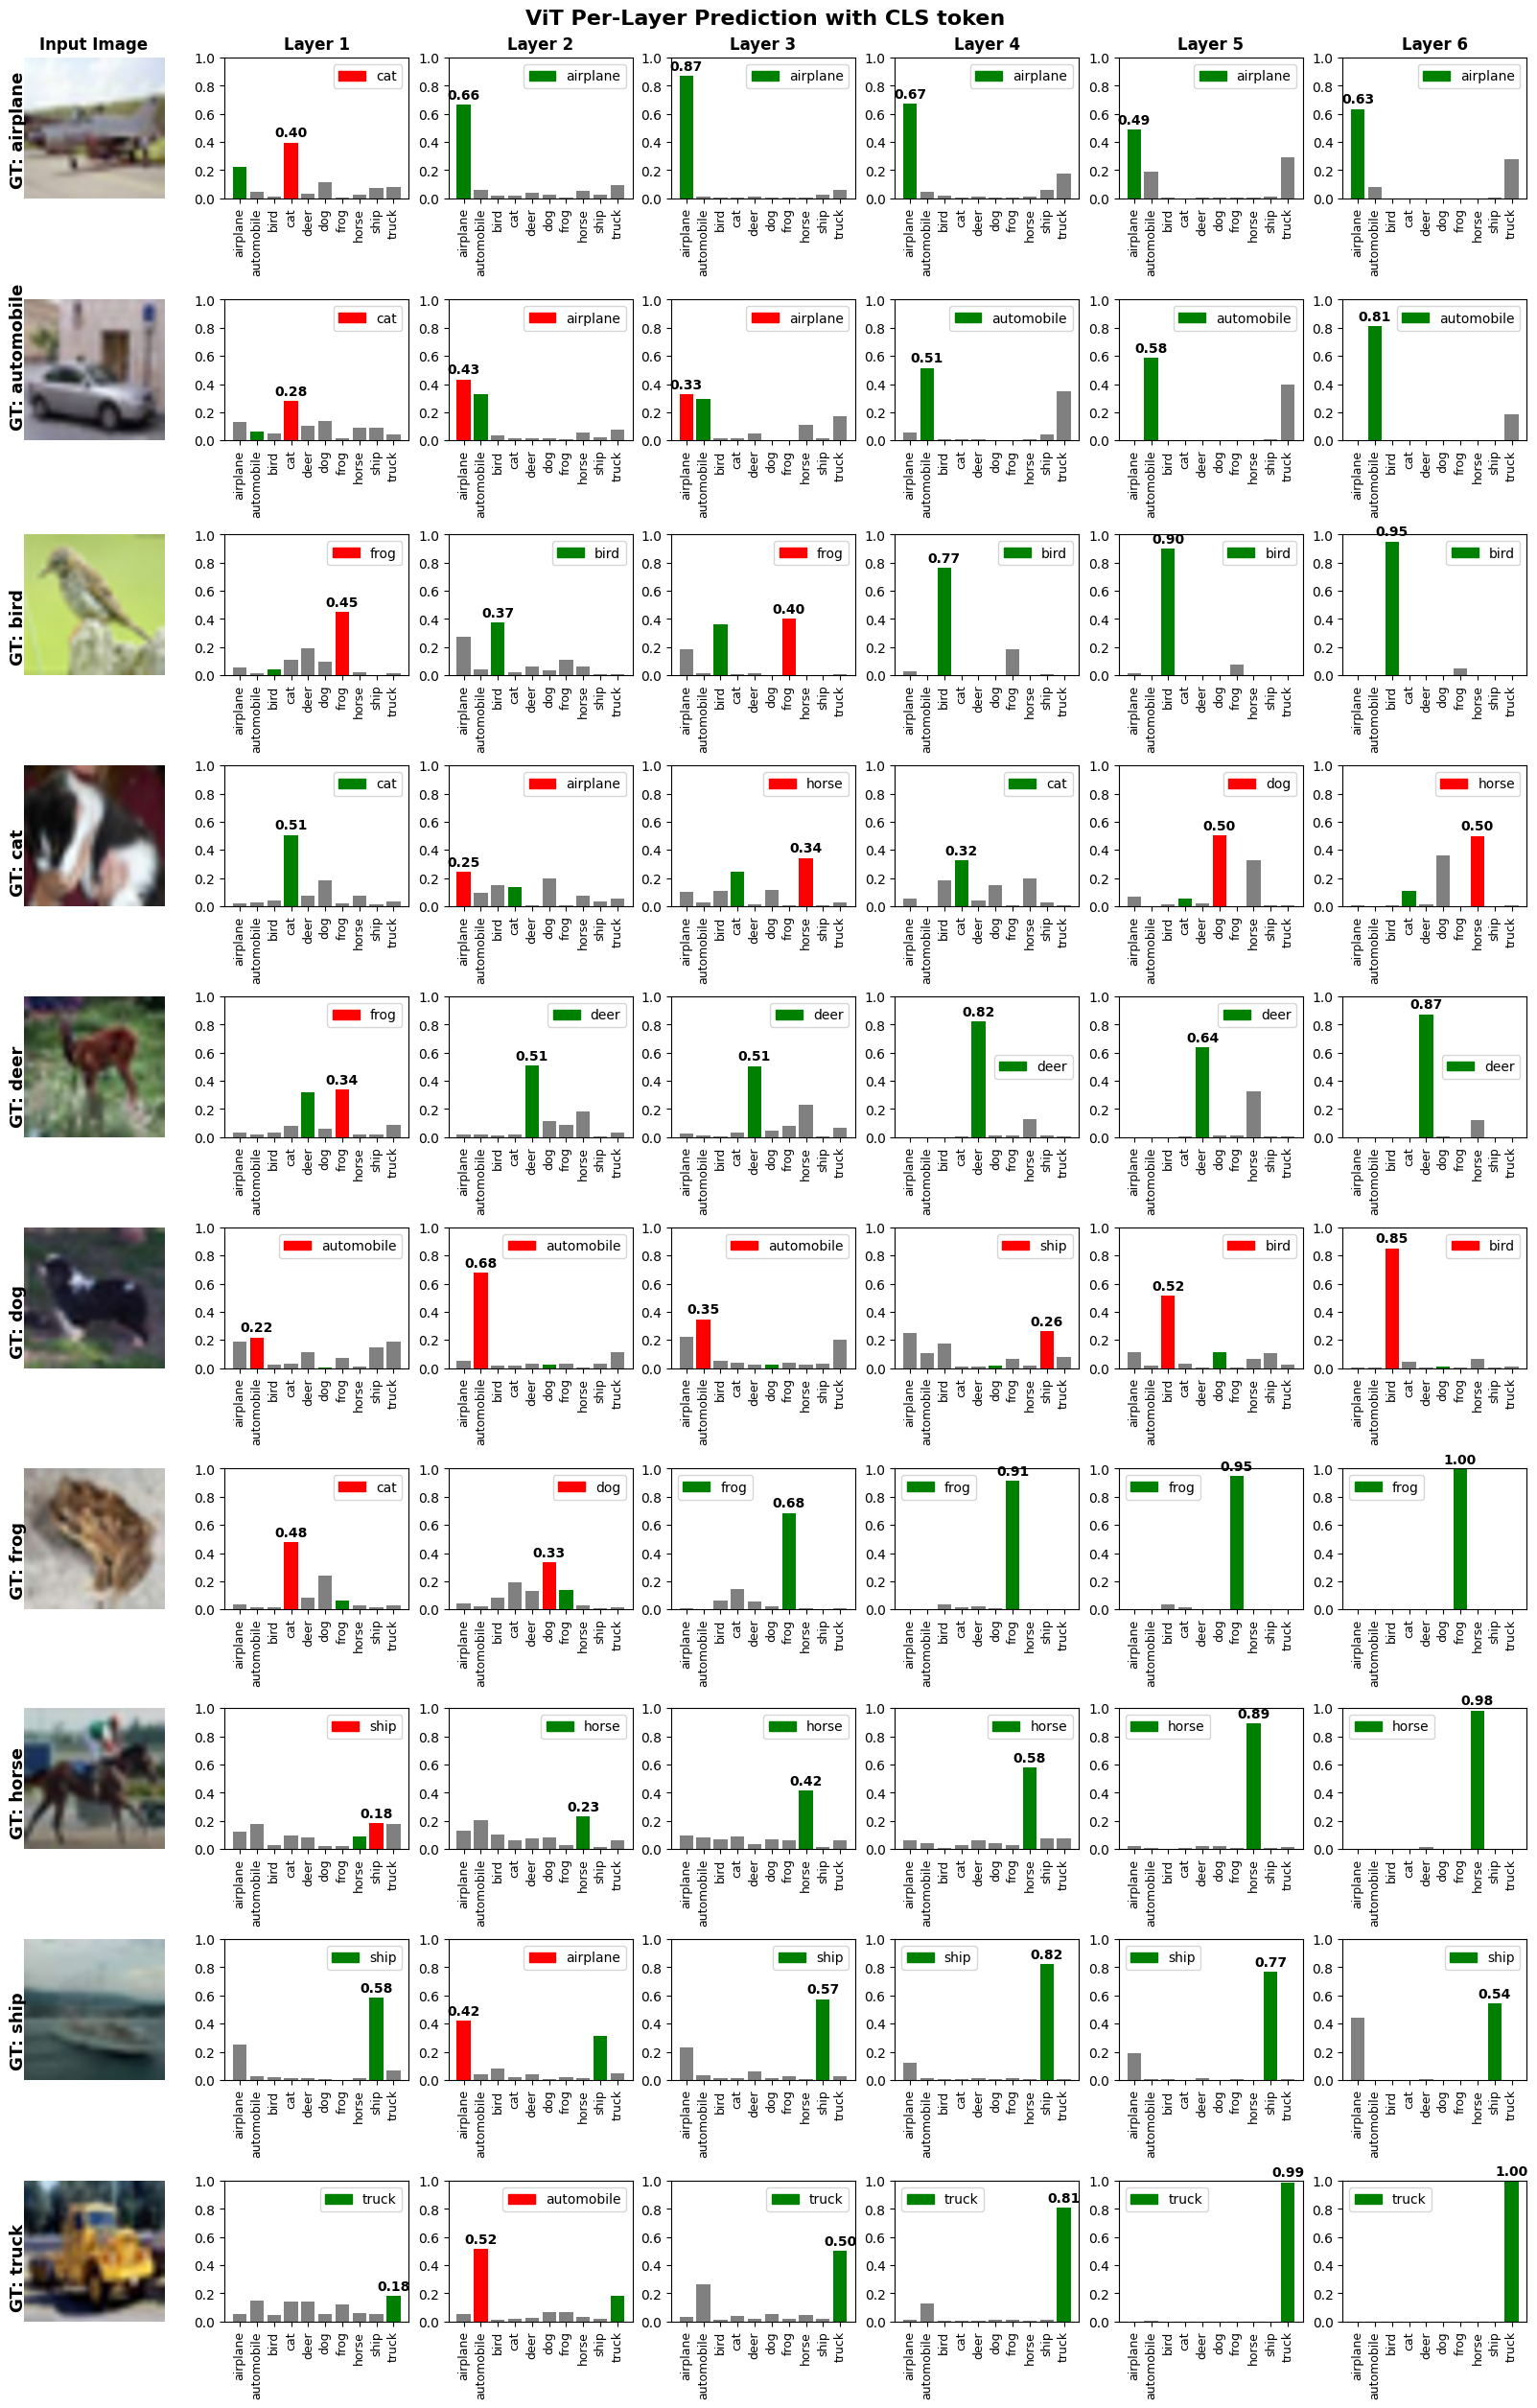

In [27]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from PIL import Image
import torch.nn.functional as F
import random
import math

# plt.ioff()

num_rows = 10
fig, axes = plt.subplots(num_rows, 7, figsize=(16, 2.5 * num_rows), constrained_layout=True)
fig.suptitle("ViT Per-Layer Prediction with CLS token", fontsize=16, weight='bold')

preds_per_layer = []

for class_idx, subset in enumerate(subsets):
    img = subset[0][0]
    input_tensor = img.unsqueeze(0).to(device)

    vit_classifier.eval()
    layer_wise = []

    with torch.no_grad():
        final_logits, layer_logits = get_per_layer_predictions(vit_classifier, input_tensor)
        for layer in layer_logits:
            probs = F.softmax(layer, dim=-1)
            pred_idx_layer = torch.argmax(probs, dim=-1).item()
            conf_layer = probs[0][pred_idx_layer].item()

            y = probs
            layer_wise.append((pred_idx_layer, conf_layer, y))

        final_probs = F.softmax(final_logits, dim=-1)
        pred_idx = torch.argmax(final_probs, dim=-1).item()
        conf = final_probs[0][pred_idx].item()

    actual_class = classes[class_idx]
    final_class = classes[pred_idx]

    img_display = plot_tensor_img(img)

    DISPLAY_SIZE = (256, 256)
    img_pil = Image.fromarray((img_display * 255).astype(np.uint8))
    img_display_upscaled = img_pil.resize(DISPLAY_SIZE, resample=Image.BICUBIC)

    ax_img = axes[class_idx, 0]
    ax_img.imshow(img_display_upscaled)
    ax_img.axis('off')

    is_final_correct = (final_class == actual_class)
    title_color = 'green' if is_final_correct else 'red'

    if class_idx == 0:
        ax_img.set_title("Input Image", fontsize=12, weight='bold')

    ax_img.text(-0.1, 0.1 , f"GT: {actual_class}", rotation=90,
                fontsize=13, weight='bold', ha='left', va='baseline', transform=ax_img.transAxes)

    layer_preds = []
    for i in range(6):
        ax = axes[class_idx, i + 1]

        pred_class_idx, conf_val, y = layer_wise[i]

        y = y.view(10).detach().cpu().numpy()
        max_class = classes[np.argmax(y)]
        colors = []
        for c in classes:
            colors.append('green' if c == actual_class else 'red' if c == max_class else 'grey')

        max_idx = classes.index(max_class)
        layer_preds.append(max_class)
        max_class_color = colors[max_idx]
        legend_handle = mpatches.Patch(color=max_class_color)
        max_bar_height = y[max_idx]

        ax.set_ylim(0, 1)
        bars = ax.bar(x=classes, height=y, color=colors)
        ax.tick_params(axis='x', labelrotation=90, labelsize=9)
        ax.legend(handles=[legend_handle], labels=[max_class])
        ax.text(
            x=max_idx, 
            y=max_bar_height + 0.02,
            s=f"{conf_val:.2f}",
            ha='center',
            va='bottom',
            fontweight='bold'
        )

        pred_class_name = classes[pred_class_idx]

        is_correct = (pred_class_name == actual_class)
        text_color = 'green' if is_correct else 'red'

        if class_idx == 0:
            ax.set_title(f"Layer {i+1}", fontsize=12, weight='bold')
    preds_per_layer.append(layer_preds)

try:
    plt.savefig("./graphs/per-layer-pred.png")
    print("Image saved in ./graphs/per-layer-pred.png")
except Exception as e:
    print(e)

plt.show()
# plt.close(fig)
# plt.ion()


In [48]:
preds_per_layer

[['cat', 'automobile', 'automobile', 'airplane', 'airplane', 'airplane'],
 ['ship', 'airplane', 'automobile', 'automobile', 'truck', 'truck'],
 ['cat', 'bird', 'bird', 'bird', 'bird', 'bird'],
 ['ship', 'cat', 'cat', 'cat', 'cat', 'cat'],
 ['deer', 'dog', 'deer', 'deer', 'deer', 'deer'],
 ['frog', 'dog', 'truck', 'truck', 'dog', 'dog'],
 ['cat', 'cat', 'frog', 'frog', 'frog', 'frog'],
 ['deer', 'dog', 'frog', 'deer', 'horse', 'horse'],
 ['ship', 'ship', 'ship', 'ship', 'ship', 'ship'],
 ['cat', 'airplane', 'airplane', 'truck', 'truck', 'truck']]

img saved.


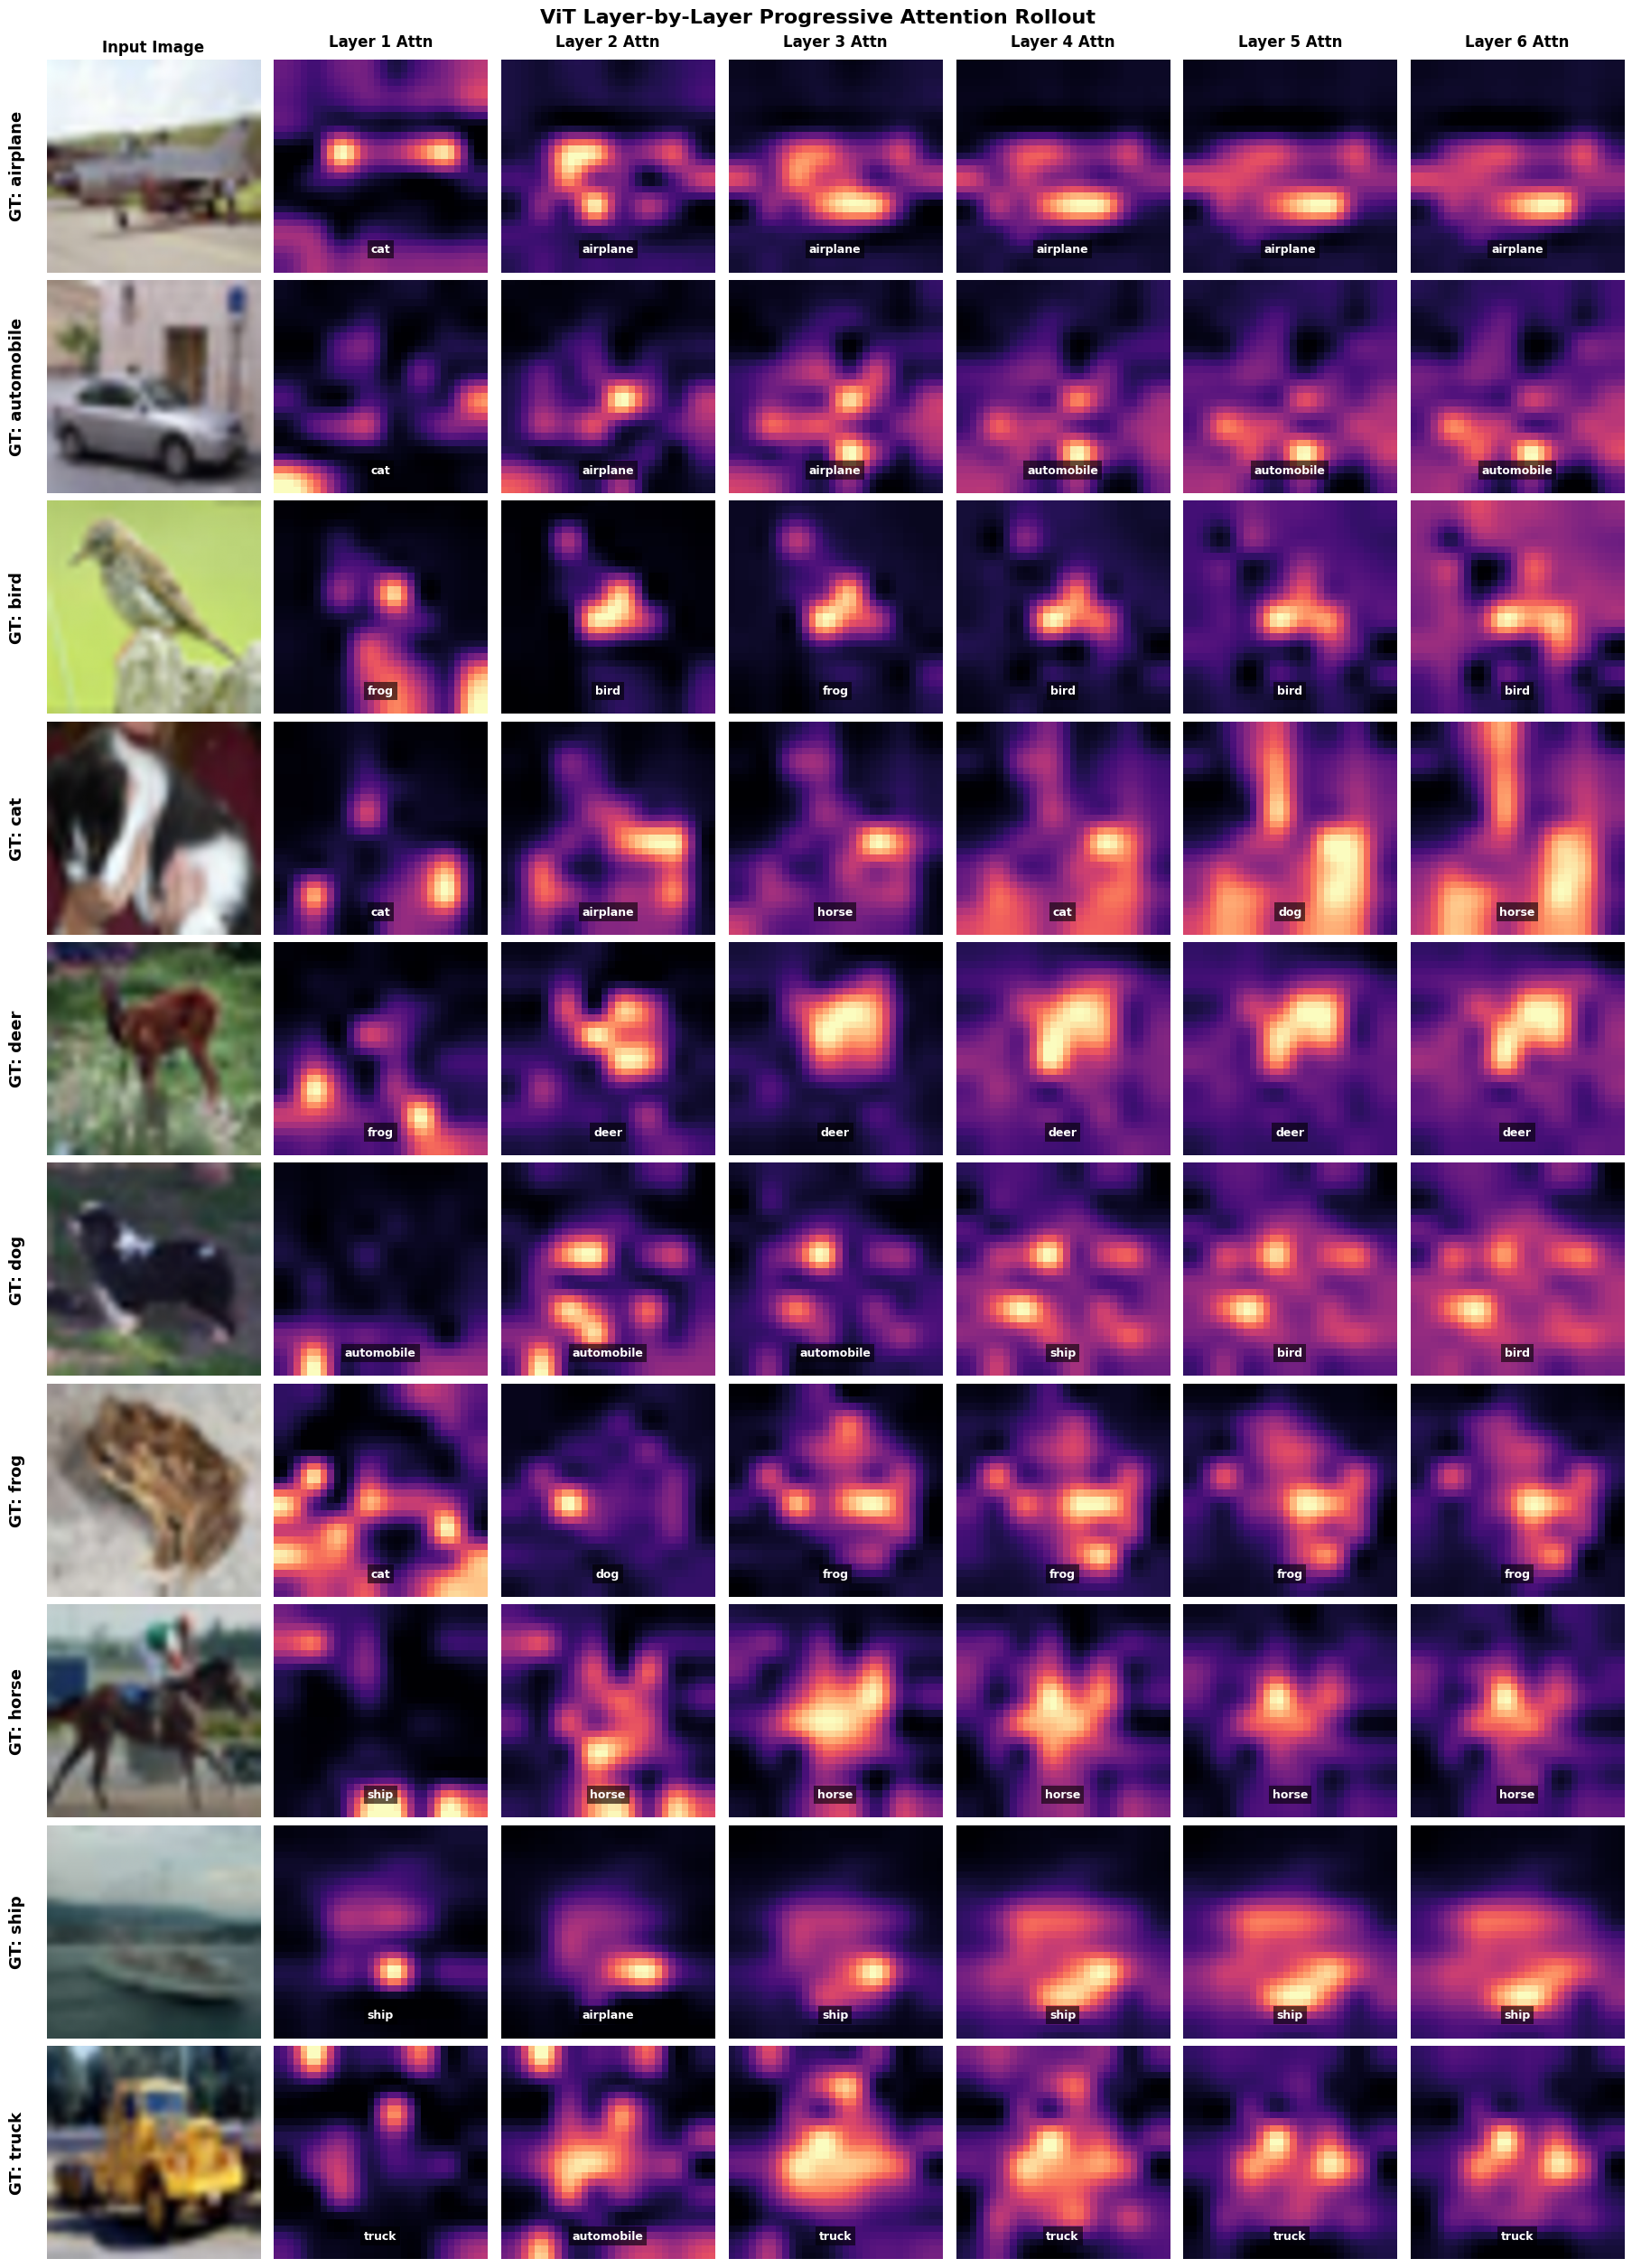

In [31]:
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image, ImageFilter
import torch
import torch.nn.functional as F

# plt.ioff()

num_rows = len(subsets)   
num_layers = 6            
img_size = 32             
num_of_patches = 64        
DISPLAY_SIZE = (256, 256)

fig, axes = plt.subplots(num_rows, num_layers + 1, figsize=(18, 2.5 * num_rows), constrained_layout=True)
fig.suptitle("ViT Layer-by-Layer Progressive Attention Rollout", fontsize=16, weight='bold')

for class_idx, subset in enumerate(subsets):
    img = subset[0][0]
    input_tensor = img.unsqueeze(0).to(device)
    
    vit_classifier.eval()
    with torch.no_grad():
        _, A = vit_classifier(input_tensor, return_attn=True)
        
    actual_class = classes[class_idx]
    
    img_display = plot_tensor_img(img)
    img_pil = Image.fromarray((img_display * 255).astype(np.uint8))
    img_display_upscaled = np.array(img_pil.resize(DISPLAY_SIZE, resample=Image.BICUBIC)) / 255.0

    ax_img = axes[class_idx, 0]
    ax_img.imshow(img_display_upscaled)
    ax_img.axis('off')
    if class_idx == 0:
        ax_img.set_title("Input Image", fontsize=12, weight='bold')
        
    ax_img.text(-0.1, 0.5, f"GT: {actual_class}", rotation=90, fontsize=13, 
                weight='bold', ha='right', va='center', transform=ax_img.transAxes)

    for i in range(num_layers):
        ax = axes[class_idx, i + 1]
        
        A_up_to_layer = A[:i+1]
        h1, h2 = attn_rollout_heatmaps(A_up_to_layer, img_size, num_of_patches)

        ax.imshow(h2, cmap='magma')
        ax.axis('off')
        
        if class_idx == 0:
            ax.set_title(f"Layer {i+1} Attn", fontsize=12, weight='bold', pad=10)

        pred_class_name = preds_per_layer[class_idx][i]
        is_correct = (pred_class_name == actual_class)
        text_color = 'white' 
        
        bbox_props = dict(boxstyle="square,pad=0.3", fc="black", alpha=0.6, ec="none")

        ax.text(0.5, 0.08, pred_class_name, color=text_color, fontsize=9, weight='bold',
                ha='center', va='bottom', transform=ax.transAxes, bbox=bbox_props)
try:
    plt.savefig("./graphs/layer_wise_attn_rollout.png", dpi=200)
    print("img saved.")
except Exception as e:
    print(f"Error writing plot output: {e}")

plt.show()
# plt.close(fig)
# plt.ion()

In [32]:
selector = ClassSampler(test_dataset, num_per_class=2)
subsets1 = selector.get_subsets()

In [23]:
# selector.lock(0)
# selector.unlock(1)
# selector.lock(2)
# selector.unlock(3)
# selector.lock(4)
# selector.unlock(5)
# selector.unlock(6)
# selector.lock(7)
# selector.lock(8)
# selector.lock(9)

In [24]:

# selector.reshuffle()
# subsets1 = selector.get_subsets()

Image saved


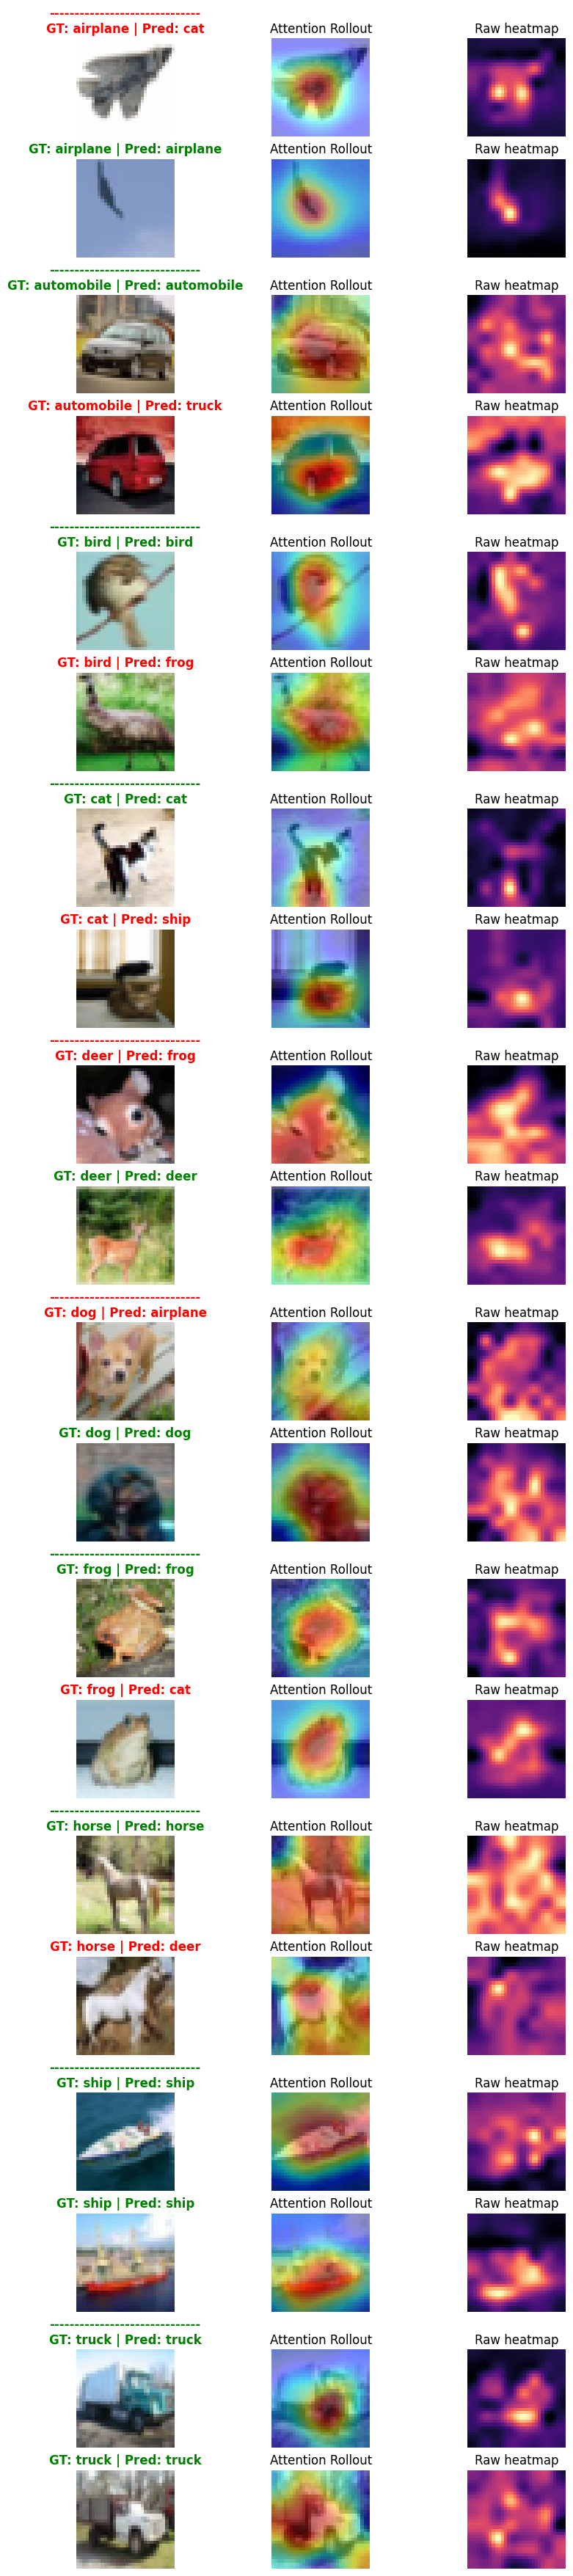

In [33]:
num_imgs = 2
num_cols = 3
num_classes = 10

fig, axes = plt.subplots(num_imgs * num_classes, num_cols, 
                         figsize=(8, 35), layout="constrained")

row = 0

for class_idx, subset in enumerate(subsets1):
    for i, v in enumerate(subset):
        pred_class, A = get_preds(v[0])
        h1, h2 = attn_rollout_heatmaps(A, 32, 64)
        img_display = plot_tensor_img(v[0])

        text_color = "green" if (pred_class == classes[class_idx]) else "red"
        
        pre = f"{'-'*30}\n" if row % 2 == 0 else ''

        title = pre + f"GT: {classes[class_idx]} | Pred: {pred_class}"

        axes[row][0].set_title(title, color=text_color, weight='semibold')

        axes[row][0].imshow(img_display)

        axes[row][1].imshow(img_display)
        axes[row][1].imshow(h1, cmap='jet', alpha=0.45)
        axes[row][1].set_title('Attention Rollout')

        axes[row][2].set_title('Raw heatmap')
        axes[row][2].imshow(h2, cmap='magma')

        for j in range(num_cols):
            axes[row][j].axis('off')

        row += 1

plt.savefig("./graphs/per-class-attn-rollout.png")
print("Image saved")
plt.show()

In [40]:
total_params = sum(p.numel() for p in vit_classifier.parameters())
total_params

2693578

In [1]:
# import shutil
# from IPython.display import FileLink

# shutil.make_archive('download', 'zip', '/kaggle/working/graphs/')
# FileLink('download.zip')


/kaggle/working/download.zip